#  Assignment 13 Regression Case Study
# Avani Jain
#PRN: 25070126044
#AIML A2


##### Import Libraries

In [45]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.svm import SVR
import statsmodels.api as sm
from sklearn.model_selection import (train_test_split,cross_val_score,learning_curve,GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score,roc_auc_score,classification_report,roc_curve
from xgboost import XGBClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline

##### Load dataset

In [46]:
with zipfile.ZipFile("/content/CMAPSSData.zip", "r") as zip_ref:zip_ref.extractall("/content/CMAPSSData")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [47]:
os.listdir("/content/CMAPSSData")
#here i checked as it has several files

['train_FD002.txt',
 'test_FD002.txt',
 'test_FD004.txt',
 'RUL_FD002.txt',
 'test_FD003.txt',
 'Damage Propagation Modeling.pdf',
 'train_FD001.txt',
 'test_FD001.txt',
 'train_FD004.txt',
 'train_FD003.txt',
 'RUL_FD003.txt',
 'readme.txt',
 'RUL_FD001.txt',
 'RUL_FD004.txt']

In [48]:
#Set the file paths
train_path = "/content/CMAPSSData/train_FD004.txt"
test_path = "/content/CMAPSSData/test_FD004.txt"
rul_path = "/content/CMAPSSData/RUL_FD004.txt"

print("Training file:", train_path)
print("Test file:", test_path)
print("RUL file:", rul_path)

Training file: /content/CMAPSSData/train_FD004.txt
Test file: /content/CMAPSSData/test_FD004.txt
RUL file: /content/CMAPSSData/RUL_FD004.txt


#####  Load the FD004 Files


In [49]:
#Each row records an engine ID, its operating cycle, three operating settings and 21 sensor measurements.
# The training file contains complete run-to-failure trajectories
# the test file contains truncated trajectories, with the corresponding RUL labels supplied separately for each test engine.

In [50]:
columns = ["engine_id", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]

train = pd.read_csv(train_path, sep=r"\s+", header=None, names=columns)
test = pd.read_csv(test_path, sep=r"\s+", header=None, names=columns)
test_rul = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL"])

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Test RUL shape:", test_rul.shape)

display(train.head())

Training shape: (61249, 26)
Test shape: (41214, 26)
Test RUL shape: (248, 1)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754


In [51]:
print("Training data information:")
train.info()


Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61249 entries, 0 to 61248
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  61249 non-null  int64  
 1   cycle      61249 non-null  int64  
 2   setting_1  61249 non-null  float64
 3   setting_2  61249 non-null  float64
 4   setting_3  61249 non-null  float64
 5   sensor_1   61249 non-null  float64
 6   sensor_2   61249 non-null  float64
 7   sensor_3   61249 non-null  float64
 8   sensor_4   61249 non-null  float64
 9   sensor_5   61249 non-null  float64
 10  sensor_6   61249 non-null  float64
 11  sensor_7   61249 non-null  float64
 12  sensor_8   61249 non-null  float64
 13  sensor_9   61249 non-null  float64
 14  sensor_10  61249 non-null  float64
 15  sensor_11  61249 non-null  float64
 16  sensor_12  61249 non-null  float64
 17  sensor_13  61249 non-null  float64
 18  sensor_14  61249 non-null  float64
 19  sensor_15  61249 no

In [52]:
print("Missing values in training data:", int(train.isna().sum().sum()))
print("Number of training engines:", train["engine_id"].nunique())
print("Number of test engines:", test["engine_id"].nunique())

Missing values in training data: 0
Number of training engines: 249
Number of test engines: 248


In [53]:
print("\nSummary statistics:")
display(train.describe().round(2))


Summary statistics:


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,...,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00,61249.00
mean,124.33,134.31,24.00,0.57,94.03,472.88,579.42,1417.90,1201.92,8.03,...,266.74,2334.43,8067.81,9.29,0.02,347.76,2228.61,97.75,20.86,12.52
std,72.00,89.78,14.78,0.31,14.25,26.44,37.34,106.17,119.33,3.62,...,138.48,128.20,85.67,0.75,0.00,27.81,145.47,5.37,9.94,5.96
min,1.00,1.00,0.00,0.00,60.00,445.00,535.48,1242.67,1024.42,3.91,...,128.31,2027.57,7845.78,8.18,0.02,302.00,1915.00,84.93,10.16,6.08
25%,60.00,62.00,10.00,0.25,100.00,445.00,549.33,1350.55,1119.49,3.91,...,134.52,2387.91,8062.63,8.65,0.02,330.00,2212.00,100.00,10.94,6.57
50%,126.00,123.00,25.00,0.70,100.00,462.54,555.74,1367.68,1136.92,7.05,...,183.45,2388.06,8083.81,9.26,0.02,334.00,2223.00,100.00,14.93,8.96
75%,185.00,191.00,42.00,0.84,100.00,491.19,607.07,1497.42,1302.62,10.52,...,371.40,2388.17,8128.35,9.37,0.03,368.00,2324.00,100.00,28.56,17.14
max,249.00,543.00,42.01,0.84,100.00,518.67,644.42,1613.00,1440.77,14.62,...,537.49,2390.49,8261.65,11.07,0.03,399.00,2388.00,100.00,39.89,23.89


##Exploratory Data Analysis

In [54]:
#These plots help inspect engine life-cycle lengths and sensor behaviour.

##### Engine life distribution

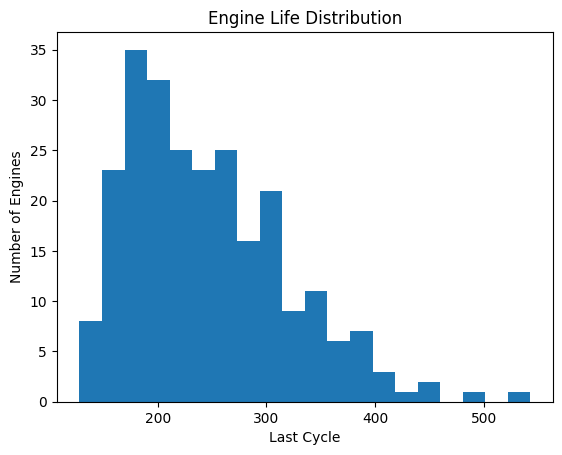

In [55]:
engine_lengths = train.groupby("engine_id")["cycle"].max()

plt.hist(engine_lengths, bins=20)
plt.title("Engine Life Distribution")
plt.xlabel("Last Cycle")
plt.ylabel("Number of Engines")
plt.show()

##### Sensor readings for one engine

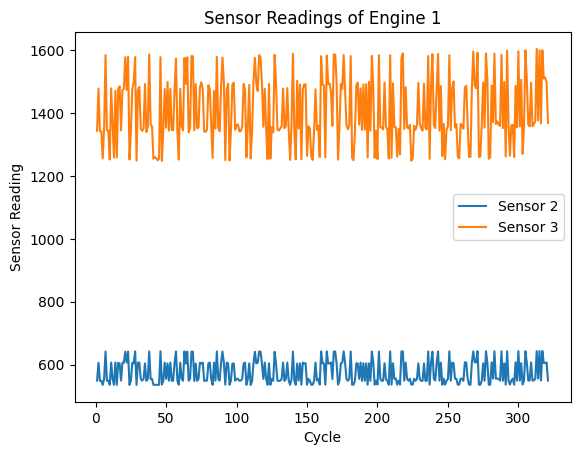

In [56]:
sample = train[train["engine_id"] == 1]

plt.plot(sample["cycle"], sample["sensor_2"], label="Sensor 2")
plt.plot(sample["cycle"], sample["sensor_3"], label="Sensor 3")

plt.title("Sensor Readings of Engine 1")
plt.xlabel("Cycle")
plt.ylabel("Sensor Reading")
plt.legend()
plt.show()

#####  Create the RUL Target and Prepare Validation Data

In [57]:
#For each training row, RUL is calculated as the engine's final training cycle minus the current cycle.
#A common prognostics convention caps RUL at 125 cycles to reduce the influence of the long, relatively healthy early-life period.
#The cap is a modeling choice, so it is stated explicitly here.

#To reduce leakage, validation engines are held out by engine ID rather than randomly splitting rows from the same engine into both sets.
#Features are scaled inside model pipelines so the scaler is fitted on training data only.

In [58]:
MAX_RUL = 125

train_model = train.copy()
train_model["RUL"] = train_model.groupby("engine_id")["cycle"].transform("max") - train_model["cycle"]
train_model["RUL"] = train_model["RUL"].clip(upper=MAX_RUL)

features = [c for c in columns if c not in ["engine_id", "cycle"]]
features = [c for c in features if train_model[c].nunique() > 1]

X = train_model[features]
y = train_model["RUL"]
groups = train_model["engine_id"]

splitter = GroupShuffleSplit(test_size=0.20, random_state=42)
train_idx, val_idx = next(splitter.split(X, y, groups))

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Features:", len(features))
print("Training rows:", X_train.shape)
print("Validation rows:", X_val.shape)
print("Training engines:", groups.iloc[train_idx].nunique())
print("Validation engines:", groups.iloc[val_idx].nunique())

Features: 24
Training rows: (49294, 24)
Validation rows: (11955, 24)
Training engines: 199
Validation engines: 50


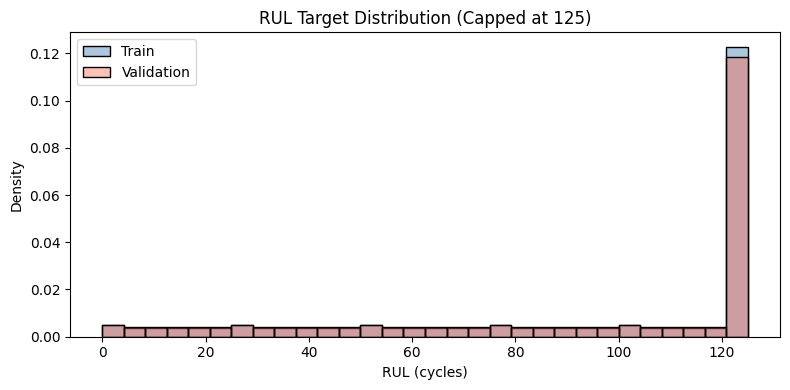

In [59]:
plt.figure(figsize=(8, 4))
sns.histplot(y_train, bins=30, color="steelblue", label="Train", stat="density", alpha=0.45)
sns.histplot(y_val, bins=30, color="tomato", label="Validation", stat="density", alpha=0.40)
plt.title("RUL Target Distribution (Capped at 125)")
plt.xlabel("RUL (cycles)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

##### Evaluation Function

In [60]:
#MAE is the average absolute prediction error in cycles. RMSE gives greater weight to large errors.
#R2 compares the model with a baseline that predicts the mean target.
#The metrics below are calculated on the same held-out validation engines for a fair comparison.

In [61]:
results = []
predictions = {}

def evaluate_model(name, model, X_train, y_train, X_val, y_val):
    model.fit(X_train, y_train)
    pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    r2 = r2_score(y_val, pred)

    results.append([name, mae, rmse, r2])
    predictions[name] = pred

    print(name)
    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2:", round(r2, 4))
    print()

    return model

results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2"])

###### Simple Linear Regression

In [62]:
#Simple Linear Regression uses one predictor only.
#Here, sensor_2 is used as the single predictor to demonstrate the simple-regression method.
# It is not assumed in advance to be the strongest individual sensor.

In [63]:
slr = LinearRegression()
slr = evaluate_model(
    "Simple Linear Regression",
    slr,
    X_train[["sensor_2"]], y_train,
    X_val[["sensor_2"]], y_val
)



Simple Linear Regression
MAE: 35.579
RMSE: 40.892
R2: -0.0008



###### Multiple Linear Regression

In [64]:
model = LinearRegression()
evaluate_model("Multiple Linear Regression", model,
               X_train, y_train, X_val, y_val)

Multiple Linear Regression
MAE: 18.759
RMSE: 22.967
R2: 0.6843



LinearRegression()

##### Ridge Regression (L2 Regularization)

In [65]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
ridge = evaluate_model("Ridge Regression (alpha=10)", ridge, X_train, y_train, X_val, y_val)

Ridge Regression (alpha=10)
MAE: 21.092
RMSE: 25.281
R2: 0.6175



##### Lasso Regression (L1 Regularization)

In [66]:
lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=20000))
lasso = evaluate_model("Lasso Regression (alpha=0.01)", lasso, X_train, y_train, X_val, y_val)

Lasso Regression (alpha=0.01)
MAE: 21.074
RMSE: 25.276
R2: 0.6176



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.775e+05, tolerance: 8.130e+03
  model = cd_fast.enet_coordinate_descent(


##### Generalized Linear Model

In [67]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_train_const = sm.add_constant(X_train_scaled)
X_val_const = sm.add_constant(X_val_scaled)

model = sm.GLM(y_train, X_train_const, family=sm.families.Gaussian())
model = model.fit()

pred = model.predict(X_val_const)

mae = mean_absolute_error(y_val, pred)
rmse = np.sqrt(mean_squared_error(y_val, pred))
r2 = r2_score(y_val, pred)

results.append(["GLM (Gaussian)", mae, rmse, r2])
predictions["GLM (Gaussian)"] = pred

print("GLM (Gaussian)")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2:", round(r2, 4))

GLM (Gaussian)
MAE: 18.759
RMSE: 22.967
R2: 0.6843


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


##### Support Vector Regression (SVR)

In [69]:
svr = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=5))

if len(X_train) > 15000:
    X_svr = X_train.sample(15000, random_state=42)
    y_svr = y_train.loc[X_svr.index]
else:
    X_svr = X_train
    y_svr = y_train

svr = evaluate_model(
    "Support Vector Regression",
    svr,
    X_svr, y_svr,
    X_val, y_val
)

Support Vector Regression
MAE: 22.251
RMSE: 28.409
R2: 0.517



##### Bagging Regressor

In [72]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
bagging = BaggingRegressor(estimator=DecisionTreeRegressor(),n_estimators=50,random_state=42,n_jobs=-1)
bagging = evaluate_model("Bagging Regressor", bagging,X_train, y_train,X_val, y_val)

Bagging Regressor
MAE: 14.287
RMSE: 20.224
R2: 0.7552



##### AdaBoost Regressor

In [75]:
from sklearn.ensemble import AdaBoostRegressor
adaboost = AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4, random_state=42), n_estimators=100, learning_rate=0.05, random_state=42)
adaboost = evaluate_model("AdaBoost Regressor", adaboost, X_train, y_train, X_val, y_val)

AdaBoost Regressor
MAE: 22.086
RMSE: 25.86
R2: 0.5998



##### Gradient Boosting Regressor

In [76]:
from sklearn.ensemble import GradientBoostingRegressor
gradient_boost = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, loss="squared_error", random_state=42)
gradient_boost = evaluate_model("Gradient Boosting Regressor", gradient_boost, X_train, y_train, X_val, y_val)

Gradient Boosting Regressor
MAE: 17.595
RMSE: 22.819
R2: 0.6883



##### XGBoost Regressor

In [78]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300,learning_rate=0.05, max_depth=6,subsample=0.8,colsample_bytree=0.8,objective="reg:squarederror",random_state=42,n_jobs=-1)
xgb = evaluate_model("XGBoost Regressor", xgb, X_train, y_train, X_val, y_val)

XGBoost Regressor
MAE: 13.832
RMSE: 19.648
R2: 0.7689



## Compare All Models

,Model,MAE,RMSE,R2
9,XGBoost Regressor,13.8323,19.6484,0.7689
6,Bagging Regressor,14.2874,20.2242,0.7552
8,Gradient Boosting Regressor,17.5950,22.8195,0.6883
4,GLM (Gaussian),18.7594,22.9666,0.6843
1,Multiple Linear Regression,18.7594,22.9666,0.6843
3,Lasso Regression (alpha=0.01),21.0741,25.2764,0.6176
2,Ridge Regression (alpha=10),21.0916,25.2811,0.6175
7,AdaBoost Regressor,22.0856,25.8605,0.5998
5,Support Vector Regression,22.2510,28.4093,0.5170
0,Simple Linear Regression,35.5791,40.8925,-0.0008


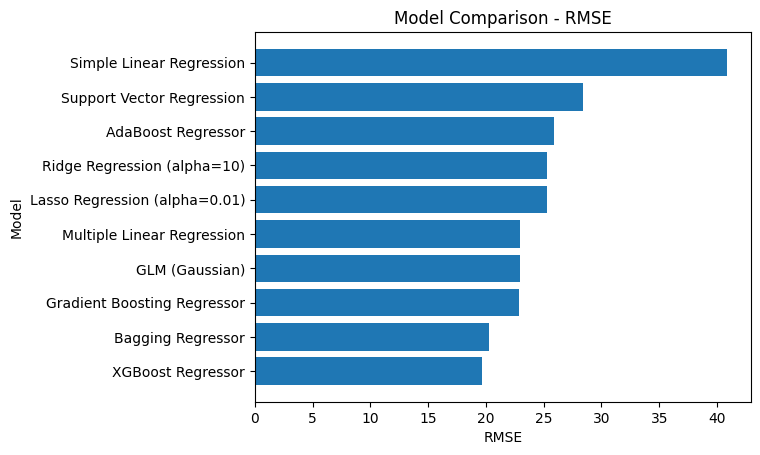

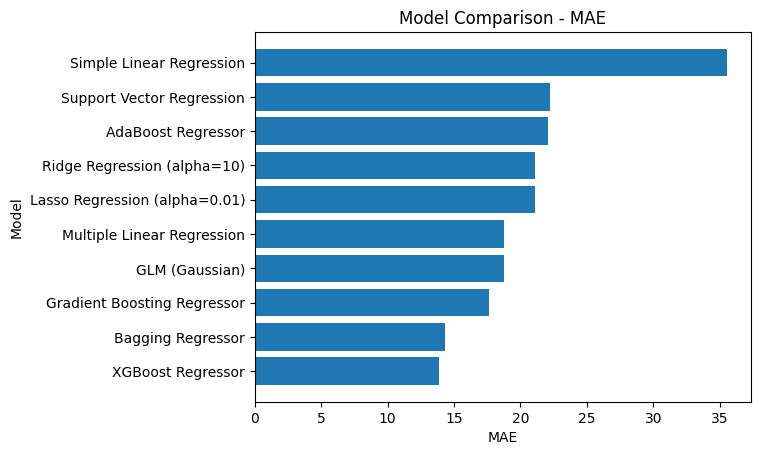

In [81]:
results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2"])
results_df = results_df.sort_values("RMSE")

display(results_df.round(4))
plt.barh(results_df["Model"], results_df["RMSE"])
plt.title("Model Comparison - RMSE")
plt.xlabel("RMSE")
plt.ylabel("Model")
plt.show()
plt.barh(results_df["Model"], results_df["MAE"])
plt.title("Model Comparison - MAE")
plt.xlabel("MAE")
plt.ylabel("Model")
plt.show()

## Actual vs Predicted and Residual Analysis

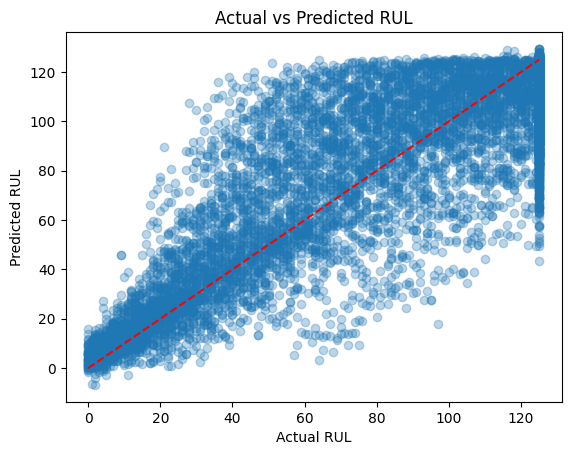

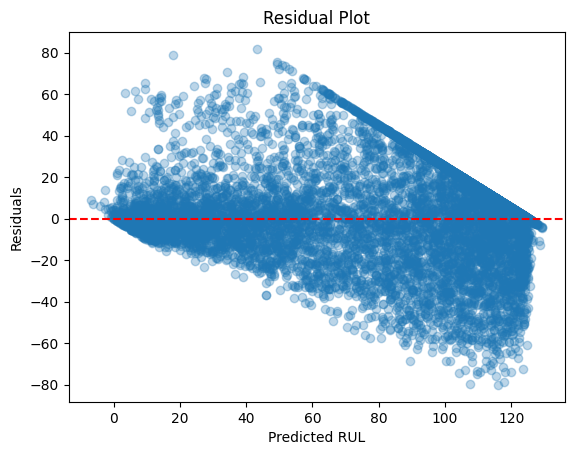

Best model: XGBoost Regressor


In [83]:
best_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_name]
plt.scatter(y_val, best_pred, alpha=0.3)
plt.plot([0, 125], [0, 125], "r--")
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")
plt.show()

residuals = y_val - best_pred
plt.scatter(best_pred, residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted RUL")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

print("Best model:", best_name)

### valuate on the Official FD004 Test Set (Optional Final Evaluation)

,Model,MAE,RMSE,R2
0,XGBoost Regressor,13.8323,19.6484,0.7689
1,Bagging Regressor,14.2874,20.2242,0.7552
2,Gradient Boosting Regressor,17.5950,22.8195,0.6883
3,GLM (Gaussian),18.7594,22.9666,0.6843
4,Multiple Linear Regression,18.7594,22.9666,0.6843
5,Lasso Regression (alpha=0.01),21.0741,25.2764,0.6176
6,Ridge Regression (alpha=10),21.0916,25.2811,0.6175
7,AdaBoost Regressor,22.0856,25.8605,0.5998
8,Support Vector Regression,22.2510,28.4093,0.5170
9,Simple Linear Regression,35.5791,40.8925,-0.0008


Best model: XGBoost Regressor


,Best Model,Test MAE,Test RMSE,Test R2
0,XGBoost Regressor,22.6502,30.3365,0.6904


Saved: regression_results.csv, final_test_results.csv, test_engine_predictions.csv


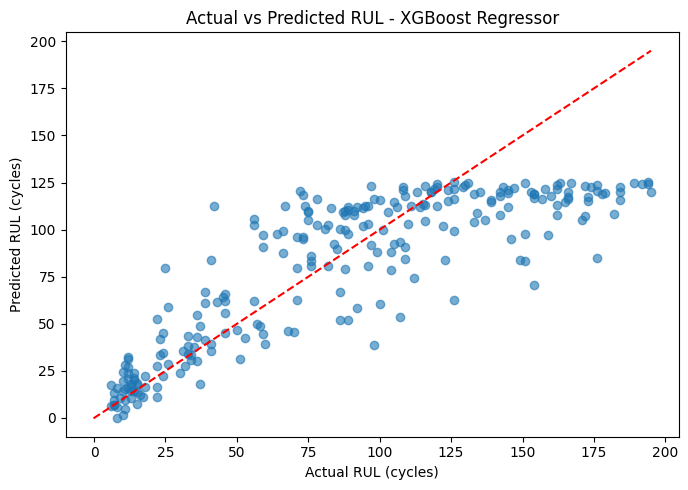

,Engine ID,Actual RUL,Predicted RUL,Absolute Error
0,1,22,52.395000,30.395
1,2,39,67.092003,28.092
2,3,107,93.333000,13.667
3,4,75,109.100998,34.101
4,5,149,84.009003,64.991
...,...,...,...,...
243,244,35,37.632999,2.633
244,245,131,124.556000,6.444
245,246,194,125.268997,68.731
246,247,112,74.306999,37.693


In [87]:
test_last = test.sort_values(["engine_id", "cycle"]).groupby("engine_id").tail(1).sort_values("engine_id")
X_test = test_last[features]
y_test = np.asarray(test_rul).reshape(-1)

assert len(X_test) == len(y_test), "Mismatch between test engines and RUL labels."

results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2"]).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv("regression_results.csv", index=False)

best_name = results_df.iloc[0]["Model"]
print("Best model:", best_name)

X_full, y_full = X[features], y
X_final = X_test

if best_name.startswith("Simple Linear Regression"):
    X_full, X_final = X[["sensor_2"]], X_test[["sensor_2"]]

if best_name == "GLM (Gaussian)":
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_full)
    X_test_scaled = scaler.transform(X_final)
    best_model = sm.GLM(
        y_full,
        sm.add_constant(X_scaled, has_constant="add"),
        family=sm.families.Gaussian()
    ).fit()
    pred = best_model.predict(sm.add_constant(X_test_scaled, has_constant="add"))

elif best_name.startswith("Simple Linear Regression") or best_name == "Multiple Linear Regression":
    best_model = LinearRegression()

elif best_name == "Ridge Regression (alpha=10)":
    best_model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))

elif best_name == "Lasso Regression (alpha=0.01)":
    best_model = make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=20000))

elif best_name in ["Support Vector Regression", "Support Vector Regression (RBF)"]:
    best_model = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=5))
    if len(X_full) > 15000:
        X_fit = X_full.sample(15000, random_state=42)
        y_fit = y_full.loc[X_fit.index]
    else:
        X_fit, y_fit = X_full, y_full

elif best_name == "Bagging Regressor":
    best_model = BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        n_estimators=50, max_samples=0.8, random_state=42, n_jobs=-1
    )

elif best_name == "AdaBoost Regressor":
    best_model = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=4, random_state=42),
        n_estimators=100, learning_rate=0.05, random_state=42
    )

elif best_name == "Gradient Boosting Regressor":
    best_model = GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05, max_depth=3,
        loss="squared_error", random_state=42
    )

elif best_name == "XGBoost Regressor":
    best_model = XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        objective="reg:squarederror", random_state=42, n_jobs=-1
    )

else:
    if best_name != "GLM (Gaussian)":
        raise ValueError(f"Unknown model: {best_name}")

if best_name != "GLM (Gaussian)":
    if best_name not in ["Support Vector Regression", "Support Vector Regression (RBF)"]:
        X_fit, y_fit = X_full, y_full
    best_model.fit(X_fit, y_fit)
    pred = best_model.predict(X_final)

final_results = pd.DataFrame([{
    "Best Model": best_name,
    "Test MAE": mean_absolute_error(y_test, pred),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    "Test R2": r2_score(y_test, pred)
}])

display(final_results.round(4))
final_results.to_csv("final_test_results.csv", index=False)

test_predictions_df = pd.DataFrame({
    "Engine ID": test_last["engine_id"].to_numpy(),
    "Actual RUL": y_test,
    "Predicted RUL": pred
})
test_predictions_df["Absolute Error"] = np.abs(
    test_predictions_df["Actual RUL"] - test_predictions_df["Predicted RUL"]
)
test_predictions_df.to_csv("test_engine_predictions.csv", index=False)

print("Saved: regression_results.csv, final_test_results.csv, test_engine_predictions.csv")

plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred, alpha=0.6)
limits = [min(y_test.min(), np.min(pred)), max(y_test.max(), np.max(pred))]
plt.plot(limits, limits, "r--")
plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title(f"Actual vs Predicted RUL - {best_name}")
plt.tight_layout()
plt.show()

display(test_predictions_df.round(3))
